# Smart Bike Rental Demand Prediction Using Machine Learning
**Predictive Analytics mini-project | exactly two models: Linear Regression (baseline) and Poisson Regression**

## Problem
Predict the hourly number of bike rentals (`cnt`) from calendar, time and weather information, using the UCI Bike Sharing dataset (`hour.csv`, Washington D.C. Capital Bikeshare, 2011-2012). Linear Regression is the baseline; Poisson Regression is a generalized linear model for count data and is part of the course syllabus.

## Notebook outline
1. Setup and data loading (with offline fallback) 2. Data-quality checks 3. Outlier inspection 4. EDA 5. Feature engineering and leakage control 6. Chronological split 7. Models 8. Evaluation 9. Diagnostics (negative predictions, overdispersion, residuals) 10. Coefficients 11. Saved outputs 12. Conclusion and limitations

## 1. Setup and data loading

In [1]:
import io, zipfile, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, PoissonRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_poisson_deviance)

RANDOM_STATE = 42          # only used for plotting samples; both models are deterministic
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
OUT = Path("outputs"); (OUT / "figures").mkdir(parents=True, exist_ok=True)
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
print("python-package versions:", f"numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}, matplotlib {matplotlib.__version__}")

python-package versions: numpy 2.3.5, pandas 2.3.3, scikit-learn 1.7.2, matplotlib 3.10.6


In [2]:
URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
LOCAL = DATA_DIR / "hour.csv"

def load_hour_csv():
    """1) try the official UCI ZIP (3 attempts); 2) fall back to the cached local copy data/hour.csv."""
    last_err = None
    for attempt in range(3):
        try:
            with urllib.request.urlopen(URL, timeout=30) as r:
                payload = r.read()
            with zipfile.ZipFile(io.BytesIO(payload)) as zf:
                raw = zf.read("hour.csv")
            LOCAL.write_bytes(raw)                      # refresh the local cache
            return pd.read_csv(io.BytesIO(raw)), "UCI download (cache refreshed)"
        except Exception as e:                         # network / zip problems
            last_err = e
    if LOCAL.exists():
        return pd.read_csv(LOCAL), f"LOCAL FALLBACK data/hour.csv (download failed: {type(last_err).__name__}: {last_err})"
    raise RuntimeError("Could not download hour.csv and no local copy exists. Download the ZIP from "
                       "https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset and put hour.csv in ./data/") from last_err

df, source = load_hour_csv()
print("Data source:", source)
print("Shape:", df.shape)
display(df.head())

Data source: UCI download (cache refreshed)
Shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 2. Data-quality checks
Missing values, duplicates, data types, valid ranges, target integrity and time-axis completeness.

In [3]:
EXPECTED_COLS = ['instant','dteday','season','yr','mnth','hr','holiday','weekday','workingday',
                 'weathersit','temp','atemp','hum','windspeed','casual','registered','cnt']
assert df.columns.tolist() == EXPECTED_COLS, "Unexpected columns"
assert df.shape == (17379, 17), f"Unexpected shape {df.shape}"

df["dteday"] = pd.to_datetime(df["dteday"])
df.info()
print("\nMissing values per column:"); display(df.isna().sum().to_frame("missing").T)
print("Duplicate rows:", df.duplicated().sum(), "| duplicate (date, hour) keys:", df.duplicated(["dteday","hr"]).sum())

# value-range validation (documented ranges from the UCI Readme)
ranges = {"season":(1,4),"yr":(0,1),"mnth":(1,12),"hr":(0,23),"holiday":(0,1),"weekday":(0,6),
          "workingday":(0,1),"weathersit":(1,4),"temp":(0,1),"atemp":(0,1),"hum":(0,1),"windspeed":(0,1),
          "casual":(0,np.inf),"registered":(0,np.inf),"cnt":(0,np.inf)}
bad = {c: int(((df[c] < lo) | (df[c] > hi)).sum()) for c, (lo, hi) in ranges.items()}
print("Out-of-range values per column:", {k: v for k, v in bad.items() if v} or "none")
assert not any(bad.values())

# target integrity
print("\ncnt dtype:", df["cnt"].dtype, "| min:", df["cnt"].min(), "| max:", df["cnt"].max(),
      "| non-negative integers:", bool((df["cnt"] >= 0).all() and (df["cnt"] == df["cnt"].round()).all()))
print("casual + registered == cnt for every row:", bool((df["casual"] + df["registered"] == df["cnt"]).all()), "(=> both must be excluded)")
print("humidity == 0 rows:", int((df["hum"] == 0).sum()), "| windspeed == 0 rows:", int((df["windspeed"] == 0).sum()))

# time-axis completeness
full_hours = pd.date_range(df["dteday"].min(), df["dteday"].max() + pd.Timedelta(hours=23), freq="h")
present = pd.DatetimeIndex(df["dteday"] + pd.to_timedelta(df["hr"], unit="h"))
print(f"\nDate range: {df.dteday.min().date()} to {df.dteday.max().date()} ({df.dteday.nunique()} days)")
print(f"Hourly rows present: {len(present)} of {len(full_hours)} possible -> {len(full_hours) - len(present)} hours have NO row")
print("Minimum cnt is", df['cnt'].min(), "-> the file contains no zero-rental hours; hours with no rentals appear to be absent rows.")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Duplicate rows: 0 | duplicate (date, hour) keys: 0
Out-of-range values per column: none

cnt dtype: int64 | min: 1 | max: 977 | non-negative integers: True
casual + registered == cnt for every row: True (=> both must be excluded)
humidity == 0 rows: 22 | windspeed == 0 rows: 2180

Date range: 2011-01-01 to 2012-12-31 (731 days)
Hourly rows present: 17379 of 17544 possible -> 165 hours have NO row
Minimum cnt is 1 -> the file contains no zero-rental hours; hours with no rentals appear to be absent rows.


**Findings.** No missing values, no duplicate rows, no duplicate (date, hour) keys, and no out-of-range values; all dtypes are as expected after converting `dteday` to a date. `cnt` is a non-negative integer (1 to 977), so it is a valid count target. `casual + registered = cnt` in every row, confirming that these two columns must be excluded.

Two data characteristics worth knowing: (1) **165 of the 17,544 possible hours have no row**, and the minimum `cnt` is 1, so hours with zero rentals appear to be missing rather than recorded as 0. The target is therefore effectively *zero-truncated*, and any hour-to-hour (lag) logic would have gaps; (2) 22 rows have humidity exactly 0 and 2,180 rows have windspeed exactly 0, which look like recording artefacts / sensor floors (the UCI file is normalised). They are kept and noted, not altered.

## 3. Outlier inspection (IQR)
Outliers are *flagged and examined*, not deleted: in demand data a high value is usually a real commuter peak, not an error.

Q1=40, Q3=281, IQR=241, fences=(-322, 642)
Flagged rows (global IQR): 505 (2.9%)
Hours of day where flagged rows occur:


hr,8,11,12,13,14,15,16,17,18,19
n,127,2,17,23,15,13,12,153,129,14


Flagged rows when IQR is applied within each (hour, workingday) group: 130 (0.7%)


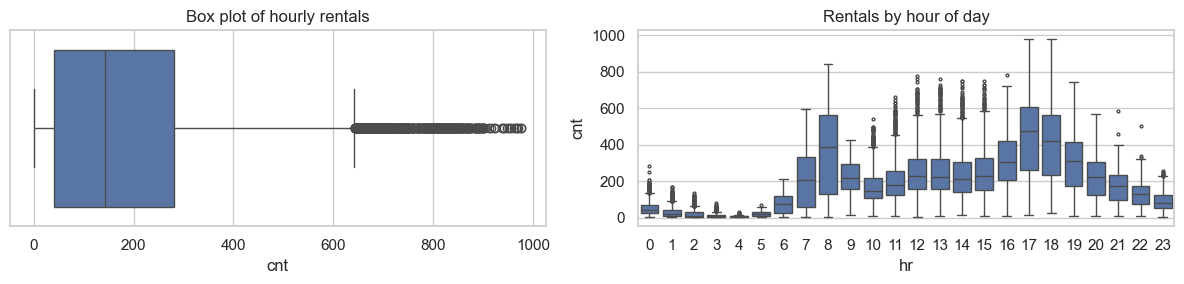

In [4]:
q1, q3 = df["cnt"].quantile([.25, .75]); iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
flag = (df["cnt"] < lower) | (df["cnt"] > upper)
print(f"Q1={q1:.0f}, Q3={q3:.0f}, IQR={iqr:.0f}, fences=({lower:.0f}, {upper:.0f})")
print(f"Flagged rows (global IQR): {flag.sum()} ({flag.mean():.1%})")
print("Hours of day where flagged rows occur:"); display(df.loc[flag, "hr"].value_counts().sort_index().to_frame("n").T)
# Conditional check: are they still unusual *within their own hour/workingday group*?
g = df.groupby(["hr", "workingday"])["cnt"]
gq1, gq3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
gflag = (df["cnt"] > gq3 + 1.5 * (gq3 - gq1)) | (df["cnt"] < gq1 - 1.5 * (gq3 - gq1))
print(f"Flagged rows when IQR is applied within each (hour, workingday) group: {gflag.sum()} ({gflag.mean():.1%})")
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=df["cnt"], ax=ax[0]); ax[0].set_title("Box plot of hourly rentals")
sns.boxplot(data=df, x="hr", y="cnt", ax=ax[1], fliersize=2); ax[1].set_title("Rentals by hour of day")
plt.tight_layout(); plt.savefig(OUT / "figures" / "outliers.png", dpi=120); plt.show()

**Interpretation.** The global IQR rule flags 505 rows (2.9 %), all at commuter-peak hours (8h and 17-18h) or the afternoon. The skewed `cnt` distribution makes a global rule misleading: when the rule is applied *within* each (hour, workingday) group only 130 rows (0.7 %) are unusual. These are genuine busy periods, not errors, so **no rows were removed** - removing them would teach the models to under-predict exactly the peaks an operator cares about.

## 4. Exploratory data analysis

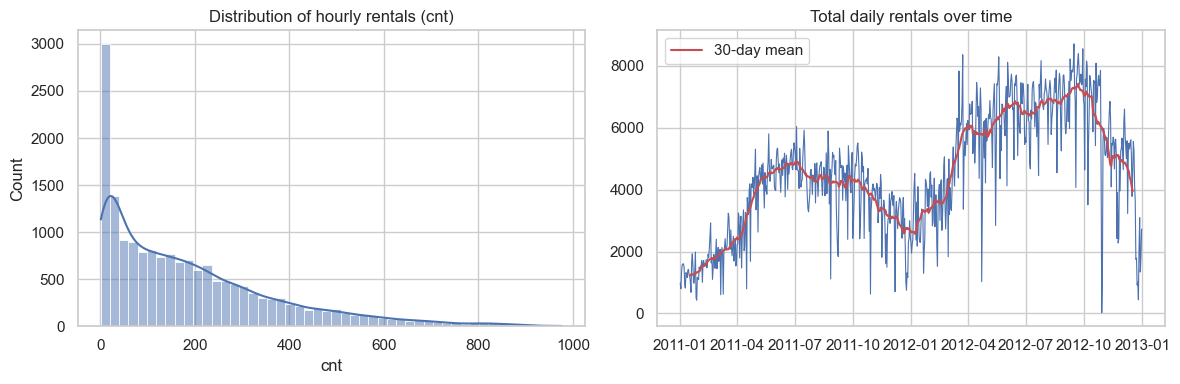

cnt mean = 189.5, variance = 32901, variance/mean = 174  (Poisson would give 1)


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["cnt"], bins=50, kde=True, ax=ax[0]); ax[0].set_title("Distribution of hourly rentals (cnt)")
daily = df.groupby("dteday")["cnt"].sum()
ax[1].plot(daily.index, daily.values, lw=.8); ax[1].plot(daily.rolling(30, center=True).mean(), color="C3", label="30-day mean")
ax[1].set_title("Total daily rentals over time"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "figures" / "eda_target_trend.png", dpi=120); plt.show()
print(f"cnt mean = {df.cnt.mean():.1f}, variance = {df.cnt.var():.0f}, variance/mean = {df.cnt.var()/df.cnt.mean():.0f}  (Poisson would give 1)")

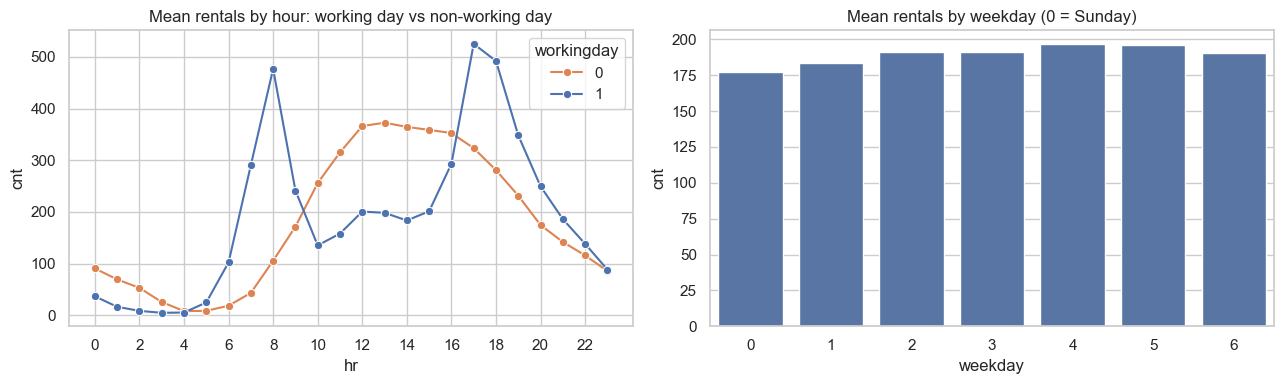

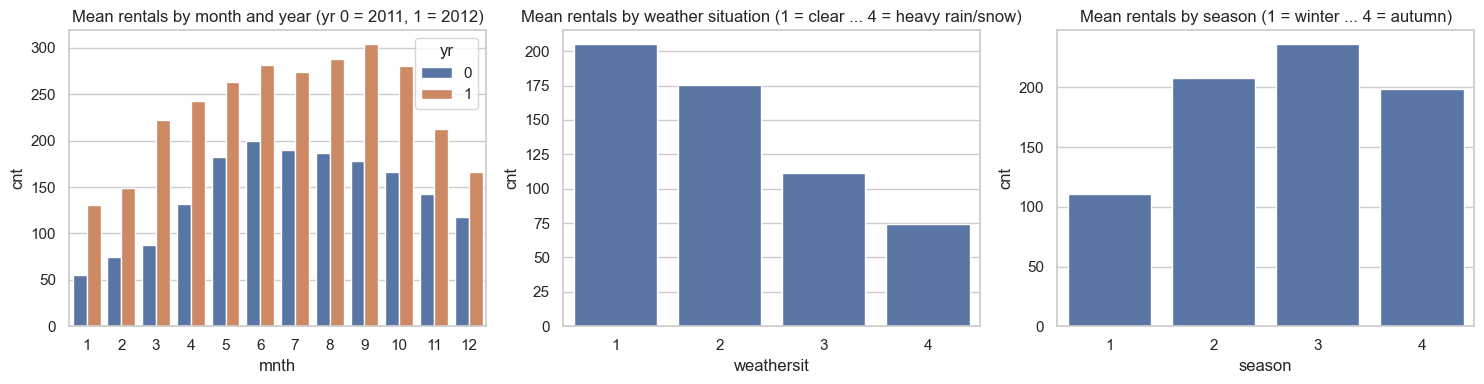

Hours per weathersit level: {1: 11413, 2: 4544, 3: 1419, 4: 3} (level 4 is very rare)


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=df, x="hr", y="cnt", hue="workingday", errorbar=None, marker="o", ax=ax[0], palette=["C1", "C0"])
ax[0].set_title("Mean rentals by hour: working day vs non-working day"); ax[0].set_xticks(range(0, 24, 2))
sns.barplot(data=df, x="weekday", y="cnt", errorbar=None, ax=ax[1], color="C0")
ax[1].set_title("Mean rentals by weekday (0 = Sunday)")
plt.tight_layout(); plt.savefig(OUT / "figures" / "eda_hour_weekday.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=df, x="mnth", y="cnt", hue="yr", errorbar=None, ax=ax[0]); ax[0].set_title("Mean rentals by month and year (yr 0 = 2011, 1 = 2012)")
sns.barplot(data=df, x="weathersit", y="cnt", errorbar=None, ax=ax[1], color="C0"); ax[1].set_title("Mean rentals by weather situation (1 = clear ... 4 = heavy rain/snow)")
sns.barplot(data=df, x="season", y="cnt", errorbar=None, ax=ax[2], color="C0"); ax[2].set_title("Mean rentals by season (1 = winter ... 4 = autumn)")
plt.tight_layout(); plt.savefig(OUT / "figures" / "eda_month_weather_season.png", dpi=120); plt.show()
print("Hours per weathersit level:", df["weathersit"].value_counts().sort_index().to_dict(), "(level 4 is very rare)")

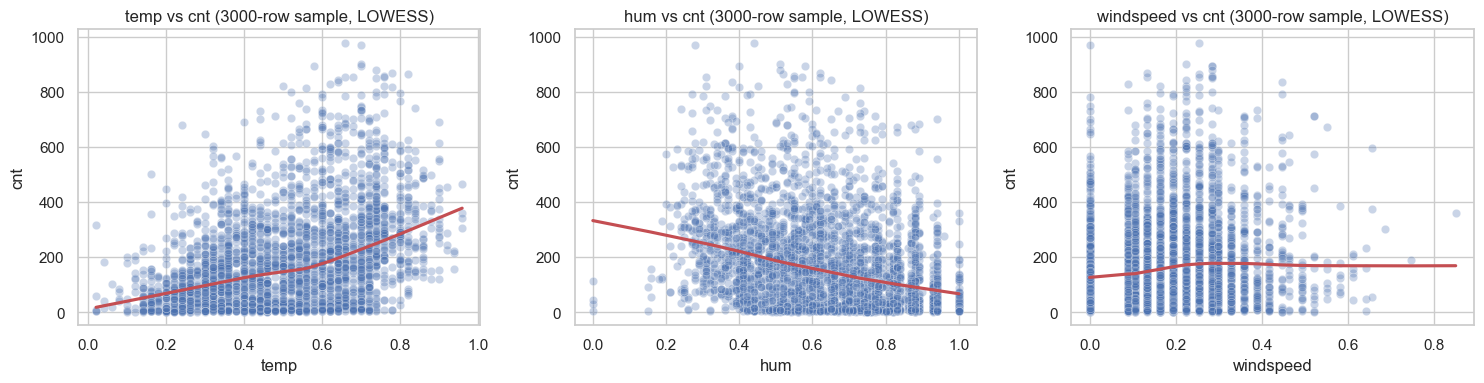

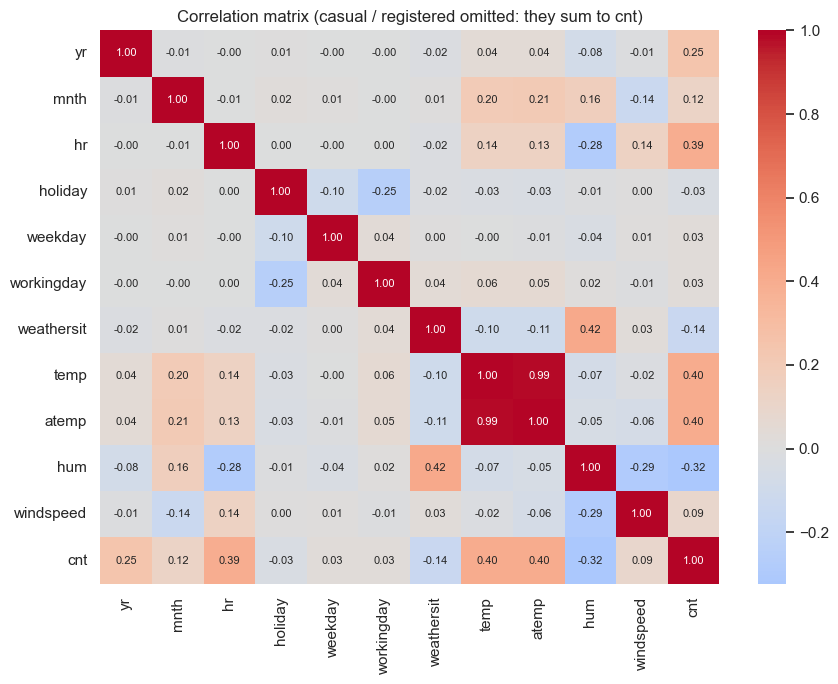

corr(temp, atemp) = 0.988 -> near-duplicate features; atemp is dropped to avoid collinearity.
corr(season, mnth) = 0.83 -> season is redundant given month.


In [7]:
sample = df.sample(3000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["temp", "hum", "windspeed"]):
    sns.scatterplot(data=sample, x=c, y="cnt", alpha=.3, ax=a); sns.regplot(data=sample, x=c, y="cnt", scatter=False, lowess=True, color="C3", ax=a)
    a.set_title(f"{c} vs cnt (3000-row sample, LOWESS)")
plt.tight_layout(); plt.savefig(OUT / "figures" / "eda_weather_scatter.png", dpi=120); plt.show()

corr_cols = ["yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit", "temp", "atemp", "hum", "windspeed", "cnt"]
plt.figure(figsize=(9, 7)); sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlation matrix (casual / registered omitted: they sum to cnt)"); plt.tight_layout()
plt.savefig(OUT / "figures" / "eda_correlation.png", dpi=120); plt.show()
print("corr(temp, atemp) =", round(df.temp.corr(df.atemp), 3), "-> near-duplicate features; atemp is dropped to avoid collinearity.")
print("corr(season, mnth) =", round(df.season.corr(df.mnth), 3), "-> season is redundant given month.")

**What the EDA shows**

- **Target shape:** right-skewed (mean 189.5, variance 32,901, variance/mean = 174), so a Poisson model's variance = mean assumption is clearly not met *marginally*; the check that matters is *conditional* on the features and is done in section 9.
- **Hour of day is the dominant driver, and it depends on the day type.** On working days there are two commuter peaks (about 480 rentals at 8h and about 525 at 17h); on non-working days there is a single broad midday hump (about 370 at 12-14h). Demand is lowest at 3-5h on both. This interaction motivates the `hr x workingday` feature below.
- **Weekday alone matters little** (mean rentals by weekday range only from about 177 to 196) once hour is considered.
- **Season / month:** mean rentals by season are 111 (winter), 208 (spring), 236 (summer), 199 (autumn); by month they rise from 94 (Jan) to about 240 (Jun and Sep) and fall to 142 (Dec).
- **Growth trend:** mean rentals were 144 in 2011 and 235 in 2012 (+63 %), visible as a rising 30-day mean. A model must capture this through `yr`; 2013 would need a level that cannot be learned from this data.
- **Weather:** more rentals in clear weather (mean 205) than mist (175) or light rain/snow (112; heavy rain/snow has only 3 hours). Rentals rise with temperature (corr 0.40) and fall with humidity (corr -0.32); windspeed has a weak relationship (corr 0.09), and the LOWESS curves show that these effects are not exactly linear.
- **Collinearity:** `temp` and `atemp` correlate at 0.99 and `season` is largely determined by `mnth` (0.83), so `atemp` and `season` are dropped.

## 5. Feature engineering and leakage control

| Decision | Reason |
|---|---|
| Drop `cnt` from inputs | It is the target. |
| Drop `casual`, `registered` | They sum exactly to `cnt` (verified above) - direct target leakage. |
| Drop `instant`, `dteday` | `instant` is a row counter, i.e. a proxy for time that cannot extrapolate; `dteday` is replaced by calendar parts. |
| Keep `yr`, `mnth`, `hr`, `weekday` | Calendar facts, known with certainty at prediction time. |
| Keep `holiday`, `workingday` | Published calendar information, known in advance. |
| Keep `temp`, `hum`, `windspeed`, `weathersit` | **Caveat:** these are the *observed* weather of the target hour. In real deployment they would have to be *forecasts*, which are noisier, so the reported accuracy is optimistic (see limitations). |
| Add `hr_workingday` (hour x workingday interaction) | Commuter peaks exist only on working days (EDA). Built from two calendar facts, so available in advance. Motivated by the EDA, see the ablation in section 8 and the limitation note on selection. |
| Drop `atemp` | corr(temp, atemp) = 0.99; near-duplicate. |
| Drop `season` | Redundant with `mnth`. |
| **No lag features** (e.g. rentals 1 hour ago) | Would be available in a real system but would change the task into short-term forecasting, and interact with the split. Not used, to keep the problem simple and leak-free. |

`hr`, `weekday`, `mnth`, `weathersit`, `hr_workingday` are encoded as **categories (one-hot)** because demand is not linear in them (e.g. hour 8 and hour 17 are peaks, hour 12 is not).

In [8]:
# Sort chronologically (date, then hour) - explicit, not relying on file order.
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)
assert df["instant"].is_monotonic_increasing, "sorted order should agree with the row counter"

TARGET = "cnt"
# hour x workingday interaction: the daily profile differs completely between working days (commuter peaks at 8h/17-18h)
# and non-working days (single midday hump) - see the EDA plot. An additive model cannot represent that.
df["hr_workingday"] = df["hr"].astype(str) + "_" + df["workingday"].astype(str)
CATEGORICAL = ["hr", "weekday", "mnth", "weathersit", "hr_workingday"]
BINARY      = ["yr", "holiday", "workingday"]
NUMERIC     = ["temp", "hum", "windspeed"]
FEATURES = CATEGORICAL + BINARY + NUMERIC
LEAKY_OR_UNUSED = ["cnt", "casual", "registered", "instant", "dteday", "atemp", "season"]

# weathersit level 4 (heavy rain/snow) occurs in only 3 of 17,379 hours -> merge into level 3 ("3 = light rain/snow or worse")
df["weathersit"] = df["weathersit"].clip(upper=3)
print("weathersit levels after merge:", df["weathersit"].value_counts().sort_index().to_dict())
X, y = df[FEATURES], df[TARGET]
assert not set(FEATURES) & set(LEAKY_OR_UNUSED)
print("Input features:", FEATURES)
print("Excluded:", LEAKY_OR_UNUSED)

weathersit levels after merge: {1: 11413, 2: 4544, 3: 1422}
Input features: ['hr', 'weekday', 'mnth', 'weathersit', 'hr_workingday', 'yr', 'holiday', 'workingday', 'temp', 'hum', 'windspeed']
Excluded: ['cnt', 'casual', 'registered', 'instant', 'dteday', 'atemp', 'season']


## 6. Chronological train / test split (80 % / 20 %)
The cut is moved to the nearest **day boundary**, so no day is shared between training and test data (a mid-day cut would put morning hours in training and afternoon hours of the *same day* in the test set).

In [9]:
raw_idx = int(len(df) * 0.80)
split_date = df["dteday"].iloc[raw_idx]                      # day containing the raw 80 % cut
split_idx = int((df["dteday"] < split_date).sum())           # first row of that day -> whole day goes to the test set
X_train, X_test = X.iloc[:split_idx].copy(), X.iloc[split_idx:].copy()
y_train, y_test = y.iloc[:split_idx].copy(), y.iloc[split_idx:].copy()
dates_test = df.loc[X_test.index, ["dteday", "hr"]]

assert df["dteday"].iloc[:split_idx].max() < df["dteday"].iloc[split_idx:].min(), "train/test dates overlap"
print(f"Train: {len(X_train)} rows ({len(X_train)/len(df):.1%}) | {df.dteday.iloc[0].date()} to {df.dteday.iloc[split_idx-1].date()}")
print(f"Test : {len(X_test)} rows ({len(X_test)/len(df):.1%}) | {df.dteday.iloc[split_idx].date()} to {df.dteday.iloc[-1].date()}")
print("Months in test:", sorted(map(int, X_test['mnth'].unique())), "| months in train:", sorted(map(int, X_train['mnth'].unique())))
print(f"Mean cnt: train {y_train.mean():.1f}, test {y_test.mean():.1f}  (test is higher partly because of the 2011 -> 2012 growth trend)")

Train: 13891 rows (79.9%) | 2011-01-01 to 2012-08-06
Test : 3488 rows (20.1%) | 2012-08-07 to 2012-12-31
Months in test: [8, 9, 10, 11, 12] | months in train: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Mean cnt: train 174.6, test 248.6  (test is higher partly because of the 2011 -> 2012 growth trend)


**Notes.** The split is chronological on whole days: 13,891 training rows (2011-01-01 to 2012-08-06) and 3,488 test rows (2012-08-07 to 2012-12-31). Because the test period is only August-December 2012, the evaluation covers **late summer to winter only**, never spring or early summer, and it falls in the higher-demand second year (test mean 248.6 vs training mean 174.6). Absolute errors on the test set are therefore expected to be larger than on an average training hour, and the result should not be read as performance over a full seasonal cycle. All 12 calendar months do occur in the training data (2011), so the one-hot month encoding has no unseen category in the test set.

## 7. Models

**Preprocessing** (fitted *only on the training rows* inside a `Pipeline`): one-hot encoding of categorical columns (`handle_unknown="ignore"`), standard scaling of the three continuous weather columns, binary columns passed through. There are no missing values, so no imputation is needed. Both models receive exactly the same transformed matrix from the same training rows.

### Linear Regression (baseline)
Ordinary least squares: `cnt = b0 + b1*x1 + ... + bp*xp`. It is simple, fast and interpretable, which makes it a standard baseline. Weaknesses for counts: it can predict negative values, assumes constant error variance (but busy hours vary much more than quiet hours) and treats effects as additive rather than multiplicative.

### Poisson Regression
A generalized linear model with a log link: `log E[cnt] = b0 + b1*x1 + ...`, i.e. `E[cnt] = exp(b0 + ...)`. Consequences: predictions are always positive, effects are multiplicative (e.g. "rainy weather multiplies expected rentals by 0.6"), and variance grows with the mean, which suits count data. **Assumptions:** counts are non-negative integers (checked), observations are conditionally independent given the features, and *equidispersion* (conditional variance = conditional mean). Hourly rentals are likely to violate the last two (neighbouring hours are autocorrelated, and counts are probably overdispersed) - this is tested below, not assumed.

`sklearn.linear_model.PoissonRegressor` adds an L2 penalty `alpha`. Its value is the **only tuned hyper-parameter**, selected by `TimeSeriesSplit` cross-validation on the **training data only** (the test set is never touched), using Poisson deviance. Linear Regression (OLS) has no hyper-parameter.

In [10]:
def make_preprocess():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CATEGORICAL),   # drop first level -> no exact collinearity for OLS
        ("num", StandardScaler(), NUMERIC),
        ("bin", "passthrough", BINARY),
    ])

# Verify target properties required by Poisson regression
assert (y_train >= 0).all() and (y_train == y_train.round()).all()
print("Target is non-negative and integer-valued: OK")

linear = Pipeline([("prep", make_preprocess()), ("model", LinearRegression())]).fit(X_train, y_train)

pois_pipe = Pipeline([("prep", make_preprocess()), ("model", PoissonRegressor(max_iter=2000))])
grid = GridSearchCV(pois_pipe, {"model__alpha": [1e-6, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]},
                    cv=TimeSeriesSplit(n_splits=5), scoring="neg_mean_poisson_deviance")
with warnings.catch_warnings():
    # Early TimeSeriesSplit folds are trained on the first months only, so later months are unseen "unknown
    # categories" there (encoded as all zeros). Expected for chronological CV; the final model sees every month.
    warnings.filterwarnings("ignore", message="Found unknown categories")
    grid.fit(X_train, y_train)
poisson = grid.best_estimator_
cv = pd.DataFrame(grid.cv_results_)[["param_model__alpha", "mean_test_score", "std_test_score"]]
cv["mean CV Poisson deviance"] = -cv.pop("mean_test_score")
cv = cv.rename(columns={"param_model__alpha": "alpha", "std_test_score": "std across folds"})
cv["alpha"] = cv["alpha"].map("{:g}".format)
display(cv.round(3))
print("Selected alpha (training-data CV only):", grid.best_params_["model__alpha"])

# Leakage proof: the fitted scaler statistics equal the TRAIN means, not the full-data means.
scaler = linear.named_steps["prep"].named_transformers_["num"]
assert np.allclose(scaler.mean_, X_train[NUMERIC].mean().values) and not np.allclose(scaler.mean_, X[NUMERIC].mean().values)
print("Scaler was fitted on training rows only: verified")
n_feat = linear.named_steps["prep"].transform(X_train.head()).shape[1]
print("Transformed feature count (identical for both models):", n_feat)

Target is non-negative and integer-valued: OK


,alpha,std across folds,mean CV Poisson deviance
0,1e-06,27.521,61.274
1,0.0001,27.516,61.258
2,0.001,27.467,61.105
3,0.01,26.947,59.687
4,0.1,21.569,50.889
5,1,3.501,40.737
6,10,11.793,73.032


Selected alpha (training-data CV only): 1
Scaler was fitted on training rows only: verified
Transformed feature count (identical for both models): 95


## 8. Evaluation on the held-out test set
Both models predict the **same** 20 % test rows. Metrics are computed on the **raw** predictions - negative Linear Regression outputs are *not* silently clipped.

In [11]:
lin_pred  = linear.predict(X_test)      # raw, may contain negatives
pois_pred = poisson.predict(X_test)     # expected counts, strictly positive

def metrics(name, pred):
    d = {"Model": name,
         "MAE": mean_absolute_error(y_test, pred),
         "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
         "R2": r2_score(y_test, pred)}
    d["Mean Poisson deviance"] = mean_poisson_deviance(y_test, pred) if (pred > 0).all() else np.nan   # undefined if any pred <= 0
    return d

results = pd.DataFrame([metrics("Linear Regression", lin_pred), metrics("Poisson Regression", pois_pred)]).set_index("Model")
display(results.round(3))
print("Mean Poisson deviance is undefined for Linear Regression when any prediction is <= 0 (NaN above).")

# Supplementary: what if the baseline's negative predictions are clipped at 0 after the fact?
lin_clip = np.clip(lin_pred, 0, None)
supp = pd.DataFrame([metrics("Linear Regression (clipped at 0)", lin_clip)]).set_index("Model")
lin_clip_pos = np.clip(lin_pred, 1e-3, None)       # deviance needs strictly positive predictions
supp["Mean Poisson deviance"] = mean_poisson_deviance(y_test, lin_clip_pos)
print("\nSupplementary - post-hoc clipped baseline (clipped to 0 for MAE/RMSE/R2; to 0.001 for deviance):")
display(supp.round(3))

print(f"\nTrain-set check (fit, not generalisation): Linear RMSE = {np.sqrt(mean_squared_error(y_train, linear.predict(X_train))):.1f}, "
      f"Poisson RMSE = {np.sqrt(mean_squared_error(y_train, poisson.predict(X_train))):.1f}")
print(f"Test target: mean = {y_test.mean():.1f}, std = {y_test.std():.1f}")
better_rmse = results["RMSE"].idxmin(); better_mae = results["MAE"].idxmin()
print(f"Lower test RMSE: {better_rmse} | Lower test MAE: {better_mae}")

,MAE,RMSE,R2,Mean Poisson deviance
Model,,,,
Linear Regression,79.491,106.934,0.765,NaN
Poisson Regression,58.913,81.148,0.865,28.179


Mean Poisson deviance is undefined for Linear Regression when any prediction is <= 0 (NaN above).

Supplementary - post-hoc clipped baseline (clipped to 0 for MAE/RMSE/R2; to 0.001 for deviance):


,MAE,RMSE,R2,Mean Poisson deviance
Model,,,,
Linear Regression (clipped at 0),79.438,106.925,0.765,49.077



Train-set check (fit, not generalisation): Linear RMSE = 71.0, Poisson RMSE = 61.3
Test target: mean = 248.6, std = 220.5
Lower test RMSE: Poisson Regression | Lower test MAE: Poisson Regression


**Ablation (disclosed):** the same two models *without* the hour x workingday interaction, to show how much that engineered feature matters. Same split, same procedure (alpha for Poisson re-tuned by training-only CV).

In [12]:
ABL_CAT = [c for c in CATEGORICAL if c != "hr_workingday"]
def abl_prep():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), ABL_CAT),
                              ("num", StandardScaler(), NUMERIC), ("bin", "passthrough", BINARY)])
abl_lin = Pipeline([("prep", abl_prep()), ("model", LinearRegression())]).fit(X_train, y_train)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Found unknown categories")
    abl_grid = GridSearchCV(Pipeline([("prep", abl_prep()), ("model", PoissonRegressor(max_iter=2000))]),
                            {"model__alpha": [1e-6, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]}, cv=TimeSeriesSplit(n_splits=5),
                            scoring="neg_mean_poisson_deviance").fit(X_train, y_train)
abl = pd.DataFrame([metrics("Linear Regression (no interaction)", abl_lin.predict(X_test)),
                    metrics("Poisson Regression (no interaction)", abl_grid.predict(X_test))]).set_index("Model")
display(abl.round(3))
print("Poisson alpha selected without the interaction:", abl_grid.best_params_["model__alpha"], "| with it:", grid.best_params_["model__alpha"])

,MAE,RMSE,R2,Mean Poisson deviance
Model,,,,
Linear Regression (no interaction),100.269,135.529,0.622,NaN
Poisson Regression (no interaction),88.794,121.806,0.695,56.141


Poisson alpha selected without the interaction: 1 | with it: 1


**Results (held-out test set, 3,488 hours; test mean = 248.6 rentals, std = 220.5).**

| Model | MAE | RMSE | R² | Mean Poisson deviance |
|---|---|---|---|---|
| Linear Regression (baseline) | 79.49 | 106.93 | 0.765 | undefined (negative predictions); 49.08 if clipped |
| Poisson Regression | **58.91** | **81.15** | **0.865** | **28.18** |

- **Poisson Regression has lower test MAE, RMSE and deviance and higher R²**; the ranking also holds in the ablation without the interaction feature (MAE 88.8 vs 100.3; RMSE 121.8 vs 135.5).
- **Size of errors:** the Poisson model is off by about 59 rentals per hour on average (about 24 % of the mean test demand), the baseline by about 79 (about 32 %). RMSE is larger than MAE for both, meaning a few large misses dominate (mostly the commuter peaks - see MAE by hour).
- **R² caveat:** R² is the share of variance explained relative to predicting the (training) mean and is based on squared error, so it is dominated by high-demand hours and ignores that count variance grows with the mean. On a test set it is not bounded below, and it says nothing about calibration. Use it alongside MAE and the deviance rather than alone.
- **Why Poisson did better here (plausible reasons, not proven):** the log link makes effects multiplicative (e.g. bad weather scales demand by a factor instead of subtracting a fixed amount, which fits both quiet nights and busy rush hours), predictions cannot go below zero, and the Poisson loss lets variance grow with the mean instead of treating a 20-rental miss at 3 a.m. the same as at 8 a.m. The linear model has to fit one additive shape everywhere.
- **Limits of the comparison:** one chronological split on a single test period, no confidence intervals, so the difference shows a consistent advantage in this test period but is not a statistical significance test. Poisson Regression had one tuned hyper-parameter (L2 `alpha`, selected on training data only) while OLS has none. In the ablation without the interaction, both models are much worse, so feature design matters about as much as model choice.

## 9. Diagnostics: negative predictions, overdispersion, residuals

In [13]:
n_neg = int((lin_pred < 0).sum())
print(f"Linear Regression: {n_neg} of {len(lin_pred)} test predictions are negative ({n_neg/len(lin_pred):.1%}); minimum = {lin_pred.min():.1f}")
print(f"Poisson Regression: {int((pois_pred <= 0).sum())} non-positive predictions; minimum = {pois_pred.min():.2f}")
print("Negative predictions by hour:", pd.Series(X_test['hr'][lin_pred < 0]).value_counts().sort_index().to_dict())

# Overdispersion: Pearson dispersion = sum((y-mu)^2/mu)/(n-p). ~1 under a correct Poisson model; >>1 = overdispersion.
p = len(poisson.named_steps["model"].coef_) + 1
def pearson_dispersion(y_true, mu, dof): return float(np.sum((y_true - mu) ** 2 / mu) / dof)
disp_train = pearson_dispersion(y_train.to_numpy(), poisson.predict(X_train), len(y_train) - p)
disp_test  = pearson_dispersion(y_test.to_numpy(), pois_pred, len(y_test))
print(f"\nPearson dispersion (Poisson model): train = {disp_train:.1f}, test = {disp_test:.1f}   (equidispersion would give ~1)")
bins = pd.qcut(pd.Series(pois_pred), 8, duplicates="drop")
vm = pd.DataFrame({"mu": pois_pred, "y": y_test.to_numpy(), "bin": bins.values}).groupby("bin", observed=True).agg(
    mean_prediction=("mu", "mean"), mean_actual=("y", "mean"), actual_variance=("y", "var"))
vm["variance / mean"] = vm["actual_variance"] / vm["mean_actual"]
display(vm.round(1))

Linear Regression: 14 of 3488 test predictions are negative (0.4%); minimum = -50.5
Poisson Regression: 0 non-positive predictions; minimum = 19.33
Negative predictions by hour: {0: 2, 1: 3, 2: 2, 3: 4, 4: 2, 5: 1}

Pearson dispersion (Poisson model): train = 17.8, test = 25.3   (equidispersion would give ~1)


,mean_prediction,mean_actual,actual_variance,variance / mean
bin,,,,
"(19.331, 50.614]",38.6,11.9,133.0,11.1
"(50.614, 92.947]",68.0,38.0,879.3,23.1
"(92.947, 148.673]",122.5,110.3,2852.5,25.9
"(148.673, 208.928]",179.3,179.4,4170.7,23.3
"(208.928, 268.527]",239.2,244.1,6971.1,28.6
"(268.527, 335.133]",299.9,317.1,7913.2,25.0
"(335.133, 455.143]",384.4,420.5,12734.3,30.3
"(455.143, 984.487]",594.3,667.2,19641.3,29.4


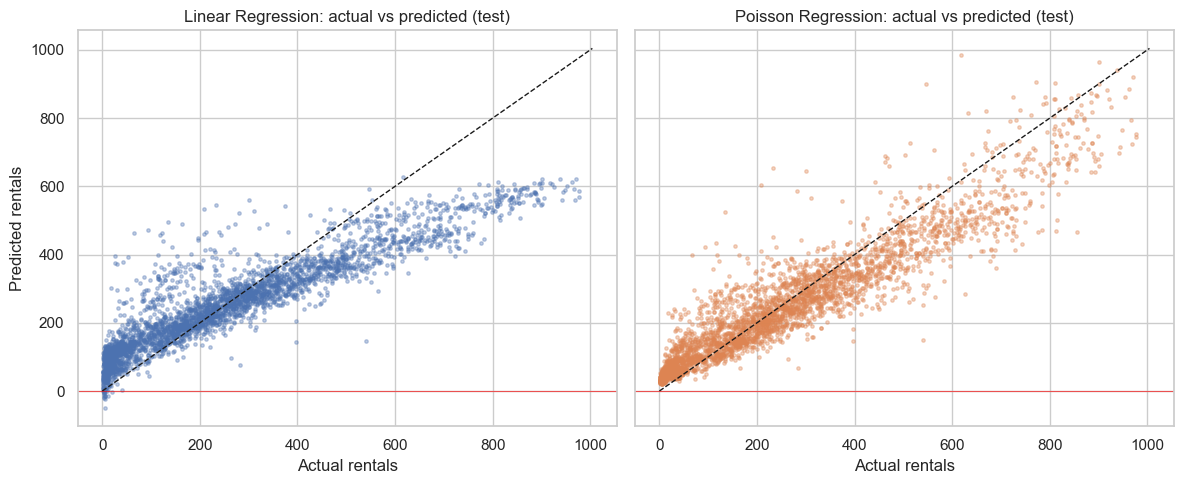

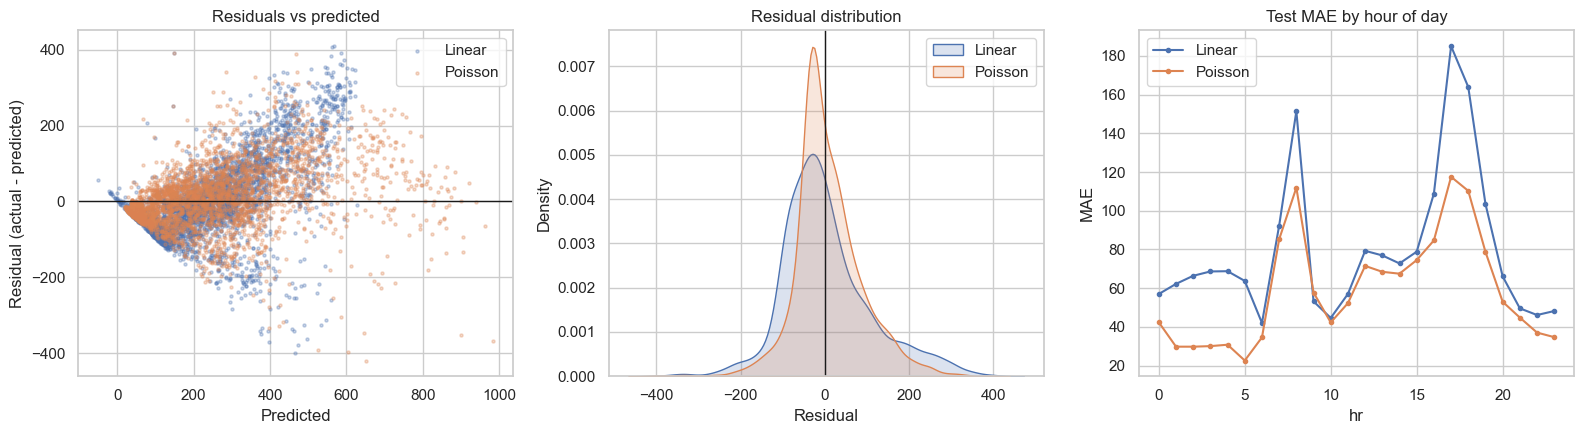

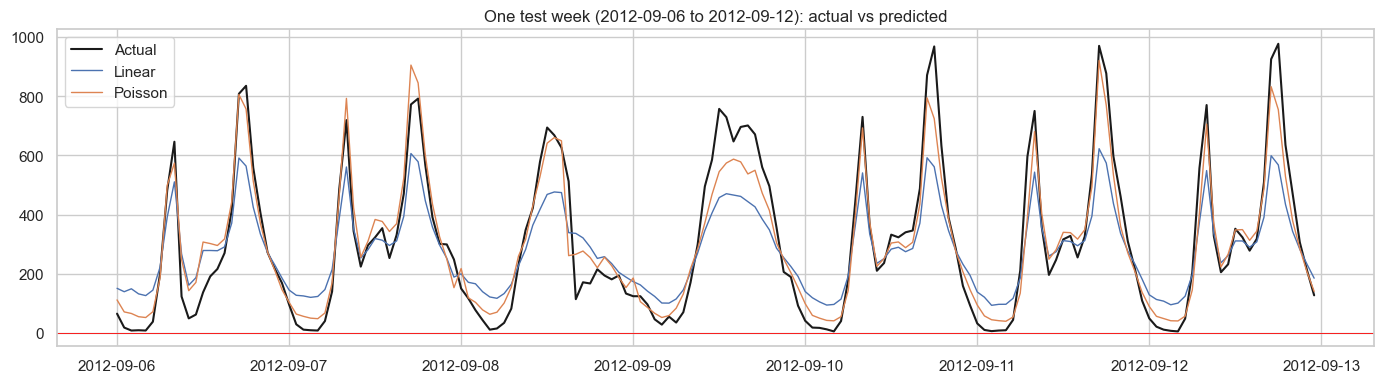

Lag-1 autocorrelation of test residuals: Linear = 0.79, Poisson = 0.73


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
lim = max(y_test.max(), lin_pred.max(), pois_pred.max()) * 1.02
for a, pred, name, c in zip(ax, [lin_pred, pois_pred], ["Linear Regression", "Poisson Regression"], ["C0", "C1"]):
    a.scatter(y_test, pred, s=6, alpha=.35, color=c); a.plot([0, lim], [0, lim], "k--", lw=1)
    a.axhline(0, color="red", lw=.8, alpha=.6); a.set_title(f"{name}: actual vs predicted (test)"); a.set_xlabel("Actual rentals")
ax[0].set_ylabel("Predicted rentals"); plt.tight_layout(); plt.savefig(OUT / "figures" / "actual_vs_predicted.png", dpi=120); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for pred, name, c in [(lin_pred, "Linear", "C0"), (pois_pred, "Poisson", "C1")]:
    ax[0].scatter(pred, y_test - pred, s=5, alpha=.3, color=c, label=name)
    sns.kdeplot(y_test - pred, ax=ax[1], color=c, label=name, fill=True, alpha=.2)
ax[0].axhline(0, color="k", lw=1); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Residual (actual - predicted)"); ax[0].set_title("Residuals vs predicted"); ax[0].legend()
ax[1].axvline(0, color="k", lw=1); ax[1].set_title("Residual distribution"); ax[1].set_xlabel("Residual"); ax[1].legend()
mae_hr = pd.DataFrame({"hr": X_test["hr"].to_numpy(), "Linear": np.abs(y_test - lin_pred).to_numpy(), "Poisson": np.abs(y_test - pois_pred).to_numpy()}).groupby("hr").mean()
mae_hr.plot(ax=ax[2], marker="o", ms=3, color=["C0", "C1"]); ax[2].set_title("Test MAE by hour of day"); ax[2].set_ylabel("MAE")
plt.tight_layout(); plt.savefig(OUT / "figures" / "residuals.png", dpi=120); plt.show()

# One test week: how do predictions follow the real series?
wk = dates_test["dteday"].dt.date.unique()[30:37]
m = dates_test["dteday"].dt.date.isin(wk).to_numpy()
t_axis = (dates_test["dteday"] + pd.to_timedelta(dates_test["hr"], unit="h"))[m]
plt.figure(figsize=(14, 4)); plt.plot(t_axis, y_test[m], "k", lw=1.5, label="Actual")
plt.plot(t_axis, lin_pred[m], color="C0", lw=1, label="Linear"); plt.plot(t_axis, pois_pred[m], color="C1", lw=1, label="Poisson")
plt.axhline(0, color="red", lw=.6); plt.title(f"One test week ({wk[0]} to {wk[-1]}): actual vs predicted"); plt.legend(); plt.tight_layout()
plt.savefig(OUT / "figures" / "test_week.png", dpi=120); plt.show()

# Residual autocorrelation (violates the independence assumption of both models if large)
r_p = (y_test - pois_pred).to_numpy(); r_l = (y_test - lin_pred).to_numpy()
print(f"Lag-1 autocorrelation of test residuals: Linear = {np.corrcoef(r_l[:-1], r_l[1:])[0,1]:.2f}, Poisson = {np.corrcoef(r_p[:-1], r_p[1:])[0,1]:.2f}")

**Interpretation**

- **Negative predictions:** Linear Regression predicts a negative number of rentals for **14 of 3,488 test hours (0.4 %)**, minimum -50.5, all between midnight and 5 a.m. Clipping them at zero barely changes MAE/RMSE (79.44 / 106.93) but shows the baseline cannot respect the non-negativity of counts. Poisson Regression has no non-positive predictions (minimum 19.3).
- **Overdispersion - the Poisson assumption does not hold.** If the Poisson model were correct, the Pearson dispersion would be about 1; it is **17.8 on the training data and 25.3 on the test data**, and the variance/mean ratio is about 11-30 in every prediction band. The Poisson model therefore **understates the true variability by more than an order of magnitude**. Its point predictions (the conditional mean) can still be useful - that is what the test metrics measure - but its implied standard errors, p-values and prediction intervals would be far too narrow and should not be trusted. A Negative Binomial / quasi-Poisson model would be the natural next step (not implemented because the project is limited to the two requested models).
- **Independence assumption also violated:** the lag-1 autocorrelation of test residuals is 0.79 (Linear) and 0.73 (Poisson), i.e. the models miss a persistent component (e.g. day-level weather, events) shared by neighbouring hours, as the one-week plot also shows (both models miss the height of whole peaks on particular days).
- **Calibration:** the Poisson model over-predicts low-demand hours (lowest prediction band: predicted 38.6 vs actual 11.9 on average) and under-predicts the busiest hours (highest band: 594 vs 667). This is typical of a strongly regularised (`alpha` = 1) mean model and of the fact that nothing in the features captures day-specific shocks (not separately tested).
- **Where errors are largest:** both models have the highest MAE at 8 a.m. and 5-6 p.m.; Poisson is clearly better in the evening peak and at night, and similar at midday.

## 10. Coefficients (interpretation)
For Poisson Regression `exp(coefficient)` is a **multiplicative effect on expected rentals** holding other features fixed (one-hot terms are relative to the dropped baseline level; continuous terms are per 1 standard deviation). For Linear Regression the coefficient is an **additive change in rentals**. These are associations learned from data, not causal effects.

In [15]:
names = linear.named_steps["prep"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
coef = pd.DataFrame({"feature": names,
                     "linear_coef (rentals)": linear.named_steps["model"].coef_,
                     "poisson_coef (log scale)": poisson.named_steps["model"].coef_})
coef["poisson_rate_ratio exp(coef)"] = np.exp(coef["poisson_coef (log scale)"])
print("Intercepts: linear =", round(float(linear.named_steps['model'].intercept_), 1), "| poisson (log) =", round(float(poisson.named_steps['model'].intercept_), 3))
print("Largest Poisson effects (by |log coefficient|; hr_* are hour effects for the baseline hour, hr_workingday_* are extra working-day shifts):")
display(coef.reindex(coef["poisson_coef (log scale)"].abs().sort_values(ascending=False).index).head(12).round(3).reset_index(drop=True))
print("Key non-hour effects:")
display(coef[coef.feature.isin(["temp", "hum", "windspeed", "yr", "workingday", "holiday", "weathersit_2", "weathersit_3"])].round(3).reset_index(drop=True))

Intercepts: linear = 23.5 | poisson (log) = 4.517
Largest Poisson effects (by |log coefficient|; hr_* are hour effects for the baseline hour, hr_workingday_* are extra working-day shifts):


,feature,linear_coef (rentals),poisson_coef (log scale),poisson_rate_ratio exp(coef)
0,hr_4,-61.015,-0.882,0.414
1,hr_workingday_8_1,204.830,0.836,2.307
2,hr_3,-57.010,-0.807,0.446
3,hr_5,-54.262,-0.733,0.481
4,hr_workingday_0_1,-90.938,-0.678,0.508
5,hr_2,-47.677,-0.674,0.509
6,hr_workingday_7_1,111.612,0.661,1.936
7,hr_17,174.835,0.639,1.894
8,hr_workingday_2_1,-65.236,-0.617,0.539
9,hr_workingday_3_1,-60.716,-0.600,0.549


Key non-hour effects:


,feature,linear_coef (rentals),poisson_coef (log scale),poisson_rate_ratio exp(coef)
0,weathersit_2,-8.720,-0.021,0.980
1,weathersit_3,-62.881,-0.391,0.676
2,temp,40.343,0.308,1.360
3,hum,-13.372,-0.073,0.930
4,windspeed,-5.792,-0.019,0.981
5,yr,84.970,0.434,1.543
6,holiday,-17.540,-0.092,0.912
7,workingday,37.645,-0.004,0.996


**Reading the coefficients (associations, not causes)**

- **Temperature:** Poisson coefficient +0.308 per standard deviation, i.e. expected rentals are about **36 % higher** (exp(0.308) = 1.36) for a one-standard-deviation warmer hour, other features fixed (the linear model says about +40 rentals).
- **Poor weather:** `weathersit_3` (light rain/snow or worse vs clear) multiplies expected rentals by about **0.68** (linear: -63 rentals). Humidity is mildly negative (x0.93 per standard deviation); windspeed is close to zero (x0.98).
- **Year:** `yr` = 2012 is about **1.54 times** the 2011 level - the business growth trend rather than a causal effect.
- **Holiday:** about 9 % fewer rentals (x0.91), other features fixed.
- **Hour:** hour effects are the largest; because of the hour x workingday interaction, the working-day commuter peaks appear as large positive `hr_workingday_*` terms (e.g. 8h on working days: x2.31 on top of the hour's base effect), and night hours as large negative terms.
- **Caution:** with interaction one-hot columns single coefficients are hard to read in isolation; `workingday` alone becomes near zero in the Poisson model (x0.996) because its effect is carried by the interaction terms, and correlated features can share or shift effects between coefficients.

## 11. Save outputs

In [16]:
pred_out = pd.DataFrame({"dteday": dates_test["dteday"].dt.date.to_numpy(), "hr": dates_test["hr"].to_numpy(), "actual_cnt": y_test.to_numpy(),
                         "linear_pred": lin_pred.round(3), "poisson_pred": pois_pred.round(3)})
pred_out.to_csv(OUT / "test_predictions.csv", index=False)
results.round(4).to_csv(OUT / "model_comparison.csv")
coef.round(5).to_csv(OUT / "coefficients.csv", index=False)
print("Saved:", sorted(str(p) for p in OUT.rglob('*') if p.is_file()))

Saved: ['outputs\\coefficients.csv', 'outputs\\figures\\actual_vs_predicted.png', 'outputs\\figures\\eda_correlation.png', 'outputs\\figures\\eda_hour_weekday.png', 'outputs\\figures\\eda_month_weather_season.png', 'outputs\\figures\\eda_target_trend.png', 'outputs\\figures\\eda_weather_scatter.png', 'outputs\\figures\\outliers.png', 'outputs\\figures\\residuals.png', 'outputs\\figures\\test_week.png', 'outputs\\model_comparison.csv', 'outputs\\test_predictions.csv']


## 12. Conclusion, limitations and leakage notes

### Conclusion
On the chronologically held-out last 20 % of the data (2012-08-07 to 2012-12-31, 3,488 hours), **Poisson Regression outperformed the Linear Regression baseline on every metric**: MAE 58.9 vs 79.5 rentals, RMSE 81.1 vs 106.9, R² 0.865 vs 0.765, and it never predicted a negative count (Linear Regression did so for 14 hours). Demand is driven mainly by the hour of day with different shapes on working vs non-working days (commuter peaks), then by the year-on-year growth trend, temperature and weather. Even the better model misses by about 59 rentals per hour on average (about 24 % of the mean test demand), mainly at rush hours.

### Limitations
- **Poisson assumptions are not satisfied.** Pearson dispersion is 17.8 (train) / 25.3 (test) versus about 1 expected, and test-residual lag-1 autocorrelation is about 0.73. The model is used as a mean predictor; its variance/interval statements should not be trusted. Negative Binomial / quasi-Poisson or time-series models would be better suited but were out of scope (exactly two models were required).
- **Single split, single test period.** Only August-December 2012 is tested; spring/early-summer behaviour and a new year's growth are unevaluated. No confidence intervals or significance tests; R² is of limited value for counts.
- **Zero-truncated, incomplete series.** 165 hours are absent and no zero-rental hours exist in the file; the models are fitted on observed hours only.
- **Feature-selection caveat.** The hour x workingday interaction was introduced after the EDA and residual inspection, and both variants (with / without it) were evaluated on the test set (shown above). The model ranking is the same in both, but the absolute scores for the final feature set are slightly optimistic because of this look at the test data. The Poisson `alpha` itself was chosen on training data only.
- **Single system and period;** associations are not causal.

### Possible remaining sources of leakage (documented, not eliminated)
1. **Observed weather as input.** `temp`, `hum`, `windspeed`, `weathersit` are the measured values of the hour being predicted. In production only a forecast is available, so real-world accuracy would be lower.
2. **Temporal dependence across the split boundary.** The split is on whole days, but neighbouring days are correlated (weather regimes, events), so training days right before the boundary are informative about the first test days. A chronological split avoids *future-to-past* leakage in the fitted model, but does not remove all temporal dependence; a gap between train and test (purging) would be stricter.
3. **Hyper-parameter selection** used `TimeSeriesSplit` inside the training data only (no test data), but model/feature choices made during the project (interaction feature) saw test results, see above.
4. **Date features are legitimate:** `yr`, `mnth`, `hr`, `weekday`, `holiday` and `workingday` are calendar facts known in advance. `instant` (a time counter) and `casual` / `registered` were excluded; no lag features of `cnt` are used.
5. **Year growth:** `yr` encodes 2011 vs 2012; forecasting 2013 would need a value never seen in training.

**Dataset citation:** Fanaee-T, H. (2013). *Bike Sharing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894. Official page: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset